In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# find the repo root no matter where the kernel was started
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

RESULTS = ROOT / "benchmarks" / "results"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def load_records(*names):
    """Load benchmark records produced by scripts/benchmark.py."""
    recs = []
    for name in names:
        with open(RESULTS / (name + ".json")) as f:
            recs.extend(json.load(f)["records"])
    return pd.DataFrame(recs)

def save_fig(fig, filename):
    fig.savefig(FIGURES / filename, dpi=150, bbox_inches="tight")
    print("saved reports/figures/" + filename)


OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k


In [2]:
import math
import struct

def count_params_safetensors(path):
    """Exact param count from a safetensors header - reads bytes, not tensors."""
    with open(path, "rb") as f:
        n = struct.unpack("<Q", f.read(8))[0]
        header = json.loads(f.read(n))
    return sum(math.prod(v["shape"]) for k, v in header.items() if k != "__metadata__")

def count_params_gpt2_config(cfg):
    """GPT-2-family param count from config only (for models whose weights are
    not stored locally, e.g. the hub-cached tiny model). wte is tied with lm_head."""
    n, L, V, P = cfg.n_embd, cfg.n_layer, cfg.vocab_size, cfg.n_positions
    inner = cfg.n_inner or 4 * n
    emb = V * n + P * n
    per_layer = (4 * n * n + 4 * n) + (2 * n * inner + inner + n) + 4 * n
    return emb + L * per_layer + 2 * n

from transformers import AutoConfig
models_dir = ROOT / ".models"

param_counts = {}
for label, local, hub in [("gpt2", models_dir / "gpt2-bf16", "gpt2"),
                          ("distilgpt2", models_dir / "distilgpt2-bf16", "distilgpt2"),
                          ("specmatch-mini-draft", models_dir / "specmatch-mini-draft", None)]:
    st = local / "model.safetensors"
    if st.exists():
        param_counts[label] = (count_params_safetensors(st), "safetensors header")
    else:  # fresh clone without prepared models: fall back to config formula
        param_counts[label] = (count_params_gpt2_config(AutoConfig.from_pretrained(hub or label)),
                               "config formula")
param_counts["sshleifer/tiny-gpt2"] = (
    count_params_gpt2_config(AutoConfig.from_pretrained("sshleifer/tiny-gpt2")), "config formula")

for name, (n, how) in param_counts.items():
    print(f"{name:26s} {n / 1e6:8.2f}M   ({how})")

gpt2                         124.44M   (safetensors header)
distilgpt2                    81.91M   (safetensors header)
specmatch-mini-draft          14.58M   (safetensors header)
sshleifer/tiny-gpt2            0.10M   (config formula)


In [3]:
expC_tiny = load_records("expC_draft_tiny")
expC_mini = load_records("expC_draft_mini")
expB_p1 = load_records("expB_K_sweep_part1")     # contains the K=4 distilgpt2 arm
expA = load_records("expA_greedy")

baseline = expA[expA["mode"] == "baseline"]
base_tps = baseline["tokens_per_sec"].mean()

arms = [
    ("tiny-gpt2 (0.1M, random)", "sshleifer/tiny-gpt2", expC_tiny),
    ("mini-draft (14.6M, ours)", "specmatch-mini-draft", expC_mini),
    ("distilgpt2 (82M, distilled)", "distilgpt2", expB_p1[expB_p1["K"] == 4]),
]
rows = []
for label, key, df in arms:
    rows.append({
        "draft": label,
        "params_M": param_counts[key][0] / 1e6,
        "acceptance": df["accepted"].sum() / df["proposed"].sum(),
        "tok_s": df["tokens_per_sec"].mean(),
        "tok_per_fwd": df["mean_tokens_per_target_forward"].mean(),
        "p50_wall_s": df["wall_time"].quantile(0.5),
    })
cmp = pd.DataFrame(rows)
cmp["speedup_vs_baseline"] = cmp["tok_s"] / base_tps
print(f"baseline (gpt2 alone): {base_tps:.2f} tok/s  [from expA_greedy]")
print(f"(distilgpt2 K=4 arm uses reps=2 from the K sweep - same settings as the other arms)")
cmp.round(3)

baseline (gpt2 alone): 12.84 tok/s  [from expA_greedy]
(distilgpt2 K=4 arm uses reps=2 from the K sweep - same settings as the other arms)


,draft,params_M,acceptance,tok_s,tok_per_fwd,p50_wall_s,speedup_vs_baseline
0,"tiny-gpt2 (0.1M, random)",0.103,0.000,4.559,0.985,14.014,0.355
1,"mini-draft (14.6M, ours)",14.577,0.006,4.244,1.008,15.183,0.331
2,"distilgpt2 (82M, distilled)",81.913,0.606,8.170,3.243,7.687,0.636


saved reports/figures/fig03_draft_size.png


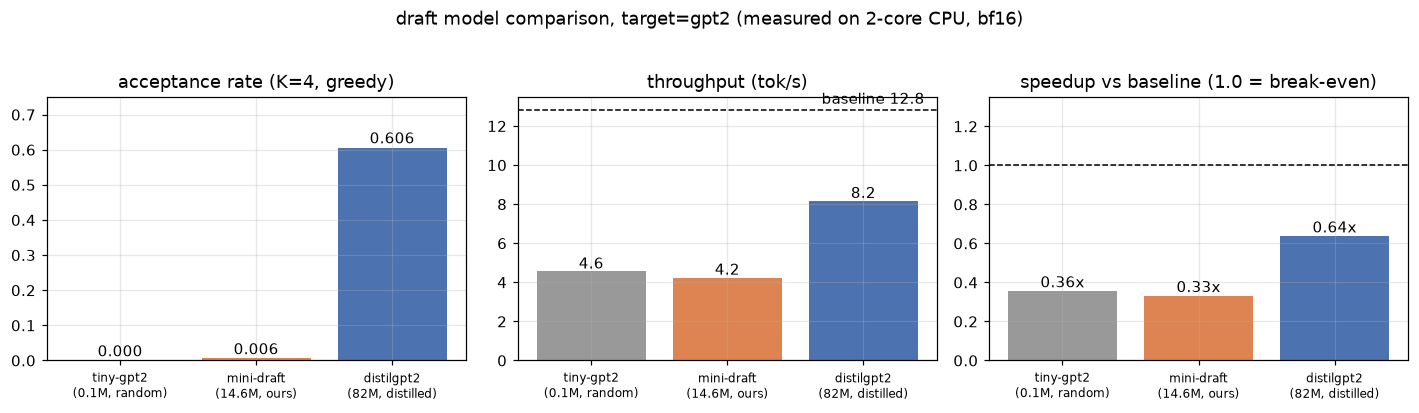

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
colors = ["#999999", "#dd8452", "#4c72b0"]
labels = [d.replace(" ", "\n", 1) for d in cmp["draft"]]

axes[0].bar(labels, cmp["acceptance"], color=colors)
axes[0].set_title("acceptance rate (K=4, greedy)")
axes[0].set_ylim(0, 0.75)
for i, v in enumerate(cmp["acceptance"]):
    axes[0].text(i, v + 0.012, f"{v:.3f}", ha="center")

axes[1].bar(labels, cmp["tok_s"], color=colors)
axes[1].axhline(base_tps, color="k", ls="--", lw=1)
axes[1].text(2.45, base_tps + 0.3, f"baseline {base_tps:.1f}", ha="right")
axes[1].set_title("throughput (tok/s)")
for i, v in enumerate(cmp["tok_s"]):
    axes[1].text(i, v + 0.15, f"{v:.1f}", ha="center")

axes[2].bar(labels, cmp["speedup_vs_baseline"], color=colors)
axes[2].axhline(1.0, color="k", ls="--", lw=1)
axes[2].set_title("speedup vs baseline (1.0 = break-even)")
axes[2].set_ylim(0, 1.35)
for i, v in enumerate(cmp["speedup_vs_baseline"]):
    axes[2].text(i, v + 0.02, f"{v:.2f}x", ha="center")

for ax in axes:
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("draft model comparison, target=gpt2 (measured on 2-core CPU, bf16)", y=1.03)
fig.tight_layout()
save_fig(fig, "fig03_draft_size.png")
plt.show()